# Library 


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# Read data


| اسم العمود             | الوصف                                                                        |
| ---------------------- | ---------------------------------------------------------------------------- |
| **id**                 | رقم فريد لكل مريض.                                                         |
| **gender**             | جنس المريض (ذكر/أنثى).                                                     |
| **age**                | عمر المريض.                                                                 |
| **hypertension**       | هل يعاني المريض من ارتفاع ضغط الدم؟                                         |
| **heart_disease**      | هل يعاني المريض من أمراض القلب؟                                            |
| **ever_married**       | هل كان المريض متزوجًا من قبل؟                                              |
| **work_type**          | نوع العمل (Private، Govt_job، Self-employed، children، Never_worked).      |
| **Residence_type**     | نوع الإقامة (Urban/Rural).                                                  |
| **avg_glucose_level**  | متوسط مستوى السكر في الدم.                                                 |
| **bmi**                | مؤشر كتلة الجسم.                                                            |
| **smoking_status**     | حالة التدخين (formerly smoked، never smoked، smokes، Unknown).            |
| **stroke**             | النتيجة المستهدفة: 1 = أصيب بالسكتة الدماغية، 0 = لا.                       |


In [2]:
df = pd.read_csv('/Users/pawn/Desktop/NTI/healthcare-dataset-stroke/healthcare-dataset-stroke-data.csv')


In [3]:
df.head() 


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [4]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [5]:
df.columns


Index(['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married',
       'work_type', 'Residence_type', 'avg_glucose_level', 'bmi',
       'smoking_status', 'stroke'],
      dtype='object')

In [6]:
df.shape


(5110, 12)

# Remove column


In [7]:
df.drop(['id'], axis=1, inplace=True)


In [8]:
print('Number of duplicate rows : ', df.duplicated().sum())

df.drop_duplicates(inplace=True)

df.reset_index(drop=True, inplace=True)


Number of duplicate rows :  0


# Data Cleaning
missing Value


In [9]:
df.isnull().sum().sort_values(ascending=False).head(8)


bmi               201
gender              0
age                 0
hypertension        0
heart_disease       0
ever_married        0
work_type           0
Residence_type      0
dtype: int64

In [10]:
# Keep smoking_status for the imputation and encoding steps below.

# Replace Nan value


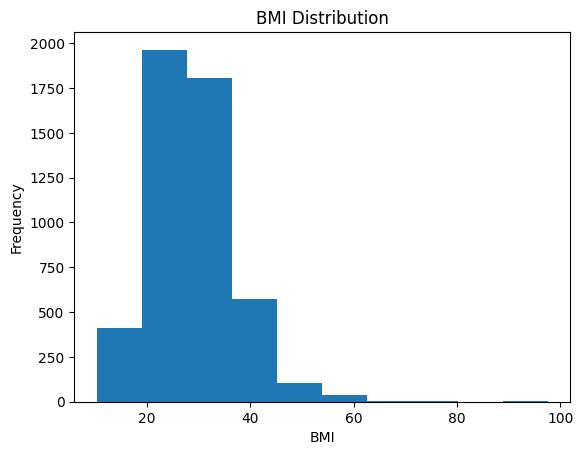

In [11]:
plt.hist(df['bmi'])
plt.title('BMI Distribution')
plt.xlabel('BMI')
plt.ylabel('Frequency')
plt.show()


In [12]:
df['bmi'].skew() 
# -0.5 ≤ skew ≤ 0.5 normal distribution
# skew > 0.5 positive skew 
# skew < -0.5 negative skew


1.0553402052962912

In [13]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(missing_values=np.nan, strategy='mean') 
#strategy = 'median', 'mean', 'constant', 'most_frequent'

imputer.fit(df[['bmi']])
df['bmi'] = imputer.transform(df[['bmi']])

#df['bmi'] = imputer.fit_transform(df[['bmi']])


In [14]:
df['bmi'].isnull().sum()


0

In [15]:
df.isnull().sum().sort_values(ascending=False).head(6)


gender           0
age              0
hypertension     0
heart_disease    0
ever_married     0
work_type        0
dtype: int64

In [16]:
imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')

#gender
#df[['gender']] = imputer.fit_transform(df[['gender']])

#ever_married
df[['ever_married']] = imputer.fit_transform(df[['ever_married']])

#work_type
df[['work_type']] = imputer.fit_transform(df[['work_type']])

#Residence_type
df[['Residence_type']] = imputer.fit_transform(df[['Residence_type']])

#smoking_status
#df[['smoking_status']] = imputer.fit_transform(df[['smoking_status']])

In [17]:
imputer = SimpleImputer(missing_values=np.nan, strategy='most_frequent')

for col in ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']:
    imputer.fit(df[[col]])
    df[[col]] = imputer.transform(df[[col]])



In [18]:
df.isnull().sum().sort_values(ascending=False).head(6)


gender           0
age              0
hypertension     0
heart_disease    0
ever_married     0
work_type        0
dtype: int64

In [19]:
df.dropna(subset='stroke', inplace=True)
df.reset_index(drop=True, inplace=True)


# Remove Duplicated


In [20]:
print('Number of duplicate rows : ', df.duplicated().sum())

df.drop_duplicates(inplace=True)

df.reset_index(drop=True, inplace=True)


Number of duplicate rows :  0


# Data Encoding


In [21]:
df.select_dtypes(include=['object']).columns


Index(['gender', 'ever_married', 'work_type', 'Residence_type',
       'smoking_status'],
      dtype='object')

In [22]:
for col in df.select_dtypes(include=['object']).columns:
    print(f'number of column {col} is : ', df[col].nunique())
    print(f'number of column {col} is : ', df[col].unique())


number of column gender is :  3
number of column gender is :  ['Male' 'Female' 'Other']
number of column ever_married is :  2
number of column ever_married is :  ['Yes' 'No']
number of column work_type is :  5
number of column work_type is :  ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
number of column Residence_type is :  2
number of column Residence_type is :  ['Urban' 'Rural']
number of column smoking_status is :  4
number of column smoking_status is :  ['formerly smoked' 'never smoked' 'smokes' 'Unknown']


## Label encoder


In [23]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['gender'] = le.fit_transform(df['gender'])
df['ever_married'] = le.fit_transform(df['ever_married'])
df['Residence_type'] = le.fit_transform(df['Residence_type'])
df['smoking_status'] = le.fit_transform(df['smoking_status'])



In [24]:
#for col in ['gender', 'ever_married', 'Residence_type', 'smoking_status']:
    #df[col] = le.fit_transform(df[col])


In [25]:
le.inverse_transform(df['smoking_status'])


array(['formerly smoked', 'never smoked', 'never smoked', ...,
       'never smoked', 'formerly smoked', 'Unknown'], dtype=object)

In [26]:
feature_names = le.classes_
print('Feature names before encoding:', feature_names)


Feature names before encoding: ['Unknown' 'formerly smoked' 'never smoked' 'smokes']


## Ordinal Encoding


In [27]:
from sklearn.preprocessing import OrdinalEncoder

ord_enc = OrdinalEncoder(categories=[['children', 'Never_worked', 'Govt_job', 'Self-employed', 'Private']])
df['work_type'] = ord_enc.fit_transform(df[['work_type']])



## LabelBinarizer


In [28]:
from sklearn.preprocessing import LabelBinarizer
lb = LabelBinarizer()
lb_encoded = lb.fit_transform(df['ever_married'])

lb_encoded[:5]


array([[1],
       [1],
       [1],
       [1],
       [1]])

In [29]:
from sklearn.preprocessing import label_binarize

ever_married_bin = label_binarize(
    df['ever_married'],
    classes=[0, 1]
)

ever_married_bin[:5]


array([[1],
       [1],
       [1],
       [1],
       [1]])

## OneHotEconder


In [30]:
df['smoking_status'].unique()


array([1, 2, 3, 0])

In [31]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown='ignore')
ohe_encoded = ohe.fit_transform(df[['work_type']]).toarray()


In [32]:
print('OneHotEncoder categories:')
print(ohe.categories_[0])


OneHotEncoder categories:
[0. 1. 2. 3. 4.]


In [33]:
ohe_df = pd.DataFrame(
    ohe_encoded,
    columns=ohe.get_feature_names_out(['work_type']),
    index=df.index
)

df = pd.concat([df, ohe_df], axis=1)


In [34]:
df.head()


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,work_type_0.0,work_type_1.0,work_type_2.0,work_type_3.0,work_type_4.0
0,1,67.0,0,1,1,4.0,1,228.69,36.600000,1,1,0.0,0.0,0.0,0.0,1.0
1,0,61.0,0,0,1,3.0,0,202.21,28.893237,2,1,0.0,0.0,0.0,1.0,0.0
2,1,80.0,0,1,1,4.0,0,105.92,32.500000,2,1,0.0,0.0,0.0,0.0,1.0
3,0,49.0,0,0,1,4.0,1,171.23,34.400000,3,1,0.0,0.0,0.0,0.0,1.0
4,0,79.0,1,0,1,3.0,0,174.12,24.000000,2,1,0.0,0.0,0.0,1.0,0.0


In [35]:
df.drop('work_type', axis=1, inplace=True)


## TargetEncoder


In [36]:
import category_encoders as ce


In [37]:
target_enc = ce.TargetEncoder(
    cols=['smoking_status', 'gender'],
    smoothing=5
)

df[['smoking_status_new', 'gender_new']] = target_enc.fit_transform(
    df[['smoking_status', 'gender']], df['stroke']
)


In [38]:
print('Final shape:', df.shape)
df.head()


Final shape: (5110, 17)


,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,smoking_status,stroke,work_type_0.0,work_type_1.0,work_type_2.0,work_type_3.0,work_type_4.0,smoking_status_new,gender_new
0,1,67.0,0,1,1,1,228.69,36.600000,1,1,0.0,0.0,0.0,0.0,1.0,0.079096,0.051064
1,0,61.0,0,0,1,0,202.21,28.893237,2,1,0.0,0.0,0.0,1.0,0.0,0.047569,0.047094
2,1,80.0,0,1,1,0,105.92,32.500000,2,1,0.0,0.0,0.0,0.0,1.0,0.047569,0.051064
3,0,49.0,0,0,1,1,171.23,34.400000,3,1,0.0,0.0,0.0,0.0,1.0,0.053232,0.047094
4,0,79.0,1,0,1,0,174.12,24.000000,2,1,0.0,0.0,0.0,1.0,0.0,0.047569,0.047094


## Frequency Encoding (Count Encoding)


In [39]:
freq = df['smoking_status'].value_counts()
df['smoking_status_freq'] = df['smoking_status'].map(freq)

df['smoking_status_freq'].head()


0     885
1    1892
2    1892
3     789
4    1892
Name: smoking_status_freq, dtype: int64

## Binary Encoding


In [40]:
encoder = ce.BinaryEncoder(cols=['smoking_status'])
encoded = encoder.fit_transform(df)

encoded.head()


,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,smoking_status_0,smoking_status_1,smoking_status_2,stroke,work_type_0.0,work_type_1.0,work_type_2.0,work_type_3.0,work_type_4.0,smoking_status_new,gender_new,smoking_status_freq
0,1,67.0,0,1,1,1,228.69,36.600000,0,0,1,1,0.0,0.0,0.0,0.0,1.0,0.079096,0.051064,885
1,0,61.0,0,0,1,0,202.21,28.893237,0,1,0,1,0.0,0.0,0.0,1.0,0.0,0.047569,0.047094,1892
2,1,80.0,0,1,1,0,105.92,32.500000,0,1,0,1,0.0,0.0,0.0,0.0,1.0,0.047569,0.051064,1892
3,0,49.0,0,0,1,1,171.23,34.400000,0,1,1,1,0.0,0.0,0.0,0.0,1.0,0.053232,0.047094,789
4,0,79.0,1,0,1,0,174.12,24.000000,0,1,0,1,0.0,0.0,0.0,1.0,0.0,0.047569,0.047094,1892


### Leave-One-Out Encoding


In [41]:
encoder = ce.LeaveOneOutEncoder(cols=['smoking_status'])
encoded = encoder.fit_transform(df[['smoking_status']], df['stroke'])

encoded.head()


,smoking_status
0,0.078054
1,0.047065
2,0.047065
3,0.052030
4,0.047065


## CatBoost Encoding (Ordered Target Encoding)


In [42]:
encoder = ce.CatBoostEncoder(cols=['smoking_status'])
df['smoking_status'] = encoder.fit_transform(df[['smoking_status']], df['stroke'])

df['smoking_status'].head()


0    0.048728
1    0.048728
2    0.524364
3    0.048728
4    0.682909
Name: smoking_status, dtype: float64

# Outliers


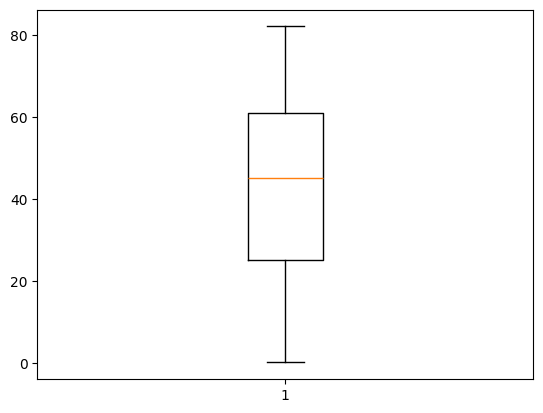

In [43]:
plt.boxplot(df['age'])
plt.show()


## Methods to Detect Outliers (IQR)


In [44]:
def remove_outliers_iqr(data, column_name='value'):
    Q1 = df[column_name].quantile(0.25)
    Q3 = df[column_name].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return df[(df[column_name] >= lower) & (df[column_name] <= upper)]
cleaned_df = remove_outliers_iqr(df, column_name='age')

print(df.shape, cleaned_df.shape)


(5110, 18) (5110, 18)


## Methods to Detect Outliers (Z-score)

![image.png](attachment:8b2c8785-3e0f-4f5c-b285-c0c0425df244.png)

Z-score works best if your data is approximately normally distributed.

| Situation                                     | Suggested Z-score threshold |
| --------------------------------------------- | --------------------------- |
| Normal data with large sample size            | **3.0** (classic standard)  |
| You want to be conservative (less strict)     | 3.5 or even 4.0             |
| You want to catch more outliers (more strict) | 2.0 or 2.5                  |
| Financial data or high-risk context           | Usually 2.5                 |


In [45]:
from scipy.stats import zscore
def remove_outliers_zscore(data, column_name='value', threshold=3.0):
    df['zscore'] = zscore(df[column_name])
    return df[np.abs(df['zscore']) < threshold]
cleaned_df = remove_outliers_zscore(df, column_name='age')

print(df.shape, cleaned_df.shape)


(5110, 19) (5110, 19)


## Methods to Detect Outliers (Isolation Forest)


In [46]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.15, random_state=42)

df['age_new'] = iso.fit_predict(df[['age']])
df_clean = df[df['age_new'] == 1].copy()
df_clean.drop(columns=['age_new'], inplace=True)
df.drop(columns=['age_new'], inplace=True)
df_clean.shape



(4391, 19)

## Methods to Detect Outliers (Local Outlier Factor (LOF))


In [47]:
from sklearn.neighbors import LocalOutlierFactor

lof = LocalOutlierFactor(contamination=0.15)
df['age_new'] = lof.fit_predict(df[['age']])
df_clean = df[df['age_new'] == 1].copy()
df_clean.drop(columns=['age_new'], inplace=True)
df.drop(columns=['age_new'], inplace=True)
df_clean.shape



(5048, 19)

## Methods to Detect Outliers (Elliptic Envelope)


In [48]:
from sklearn.covariance import EllipticEnvelope

ell = EllipticEnvelope(contamination=0.15, random_state=42)
df['age_new'] = ell.fit_predict(df[['age']])
df_clean = df[df['age_new'] == 1].copy()
df_clean.drop(columns=['age_new'], inplace=True)
df.drop(columns=['age_new'], inplace=True)
df_clean.shape


(4405, 19)

In [49]:
def estimate_contamination(df, column_name, factor=1.5):

    Q1 = df[column_name].quantile(0.25)
    Q3 = df[column_name].quantile(0.75)
    IQR = Q3 - Q1

    mask_outliers = (df[column_name] < (Q1 - factor * IQR)) | (df[column_name] > (Q3 + factor * IQR))
    contamination_value = mask_outliers.sum() / len(df)
    
    return contamination_value


In [50]:
contamination_value = estimate_contamination(df, 'age')
contamination_value


0.0

### Remove Outliers (drop them)
Drops rows with values outside the IQR boundaries (common way to remove few outliers).


In [51]:
def remove_outliers_drop(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return df[(df[column] >= lower) & (df[column] <= upper)]
cleaned_df = remove_outliers_drop(df, 'age')

print(df.shape, cleaned_df.shape)


(5110, 19) (5110, 19)


### Cap (Winsorize)
Replaces extreme values at the top and bottom (e.g., top 5%, bottom 5%) with nearest non-extreme values to reduce their influence.


In [52]:
from scipy.stats.mstats import winsorize

def cap_outliers(data, limits=(0.05, 0.05)):
    return winsorize(data, limits=limits)

cleaned_df = cap_outliers(df['age'], (0.05, 0.05))

print(df.shape, cleaned_df.shape)


(5110, 19) (5110,)


### Clip (Set min/max thresholds)
Directly restricts values to be within fixed min and max thresholds.


In [53]:
df['age'].max(), df['age'].min()


(82.0, 0.08)

In [54]:
def clip_data(data, min_value, max_value):
    return np.clip(data, min_value, max_value)
    
cleaned_df = clip_data(df['age'], 5, 90)

print(df.shape, cleaned_df.shape)


(5110, 19) (5110,)


In [55]:
X = df.drop(['stroke', 'zscore'], axis=1)


In [56]:
X.head()


,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,smoking_status,work_type_0.0,work_type_1.0,work_type_2.0,work_type_3.0,work_type_4.0,smoking_status_new,gender_new,smoking_status_freq
0,1,67.0,0,1,1,1,228.69,36.600000,0.048728,0.0,0.0,0.0,0.0,1.0,0.079096,0.051064,885
1,0,61.0,0,0,1,0,202.21,28.893237,0.048728,0.0,0.0,0.0,1.0,0.0,0.047569,0.047094,1892
2,1,80.0,0,1,1,0,105.92,32.500000,0.524364,0.0,0.0,0.0,0.0,1.0,0.047569,0.051064,1892
3,0,49.0,0,0,1,1,171.23,34.400000,0.048728,0.0,0.0,0.0,0.0,1.0,0.053232,0.047094,789
4,0,79.0,1,0,1,0,174.12,24.000000,0.682909,0.0,0.0,0.0,1.0,0.0,0.047569,0.047094,1892


In [57]:
y = df['stroke']


In [58]:
y.head()


0    1
1    1
2    1
3    1
4    1
Name: stroke, dtype: int64

# Spliting Data 
### train test split


In [59]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                   test_size=0.20, random_state=100, stratify=None)

print('X_train = ', X_train.shape, ' y_train = ', y_train.shape)
print('X_test  = ', X_test.shape, ' y_test  = ', y_test.shape)


X_train =  (4088, 17)  y_train =  (4088,)
X_test  =  (1022, 17)  y_test  =  (1022,)


# Data Scaling  ( Normalization)


In [60]:
X_train.describe()


,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,smoking_status,work_type_0.0,work_type_1.0,work_type_2.0,work_type_3.0,work_type_4.0,smoking_status_new,gender_new,smoking_status_freq
count,4088.000000,4088.000000,4088.000000,4088.000000,4088.000000,4088.000000,4088.000000,4088.000000,4088.000000,4088.000000,4088.000000,4088.000000,4088.000000,4088.000000,4088.000000,4088.000000,4088.000000
mean,0.410714,43.096194,0.095646,0.054061,0.651419,0.506115,105.481871,28.813851,0.190103,0.134051,0.003914,0.125978,0.157290,0.578767,0.048755,0.048723,1441.351027
std,0.492521,22.584921,0.294141,0.226165,0.476579,0.500024,44.524493,7.712778,0.231132,0.340749,0.062446,0.331866,0.364118,0.493817,0.016271,0.001953,444.964788
min,0.000000,0.080000,0.000000,0.000000,0.000000,0.000000,55.120000,10.300000,0.030472,0.000000,0.000000,0.000000,0.000000,0.000000,0.030440,0.047094,789.000000
25%,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,77.095000,23.600000,0.060622,0.000000,0.000000,0.000000,0.000000,0.000000,0.030440,0.047094,885.000000
50%,0.000000,44.000000,0.000000,0.000000,1.000000,1.000000,91.835000,28.400000,0.096562,0.000000,0.000000,0.000000,0.000000,1.000000,0.047569,0.047094,1544.000000
75%,1.000000,61.000000,0.000000,0.000000,1.000000,1.000000,113.630000,32.700000,0.194783,0.000000,0.000000,0.000000,0.000000,1.000000,0.053232,0.051064,1892.000000
max,2.000000,82.000000,1.000000,1.000000,1.000000,1.000000,271.740000,97.600000,0.989546,1.000000,1.000000,1.000000,1.000000,1.000000,0.079096,0.051064,1892.000000


## MinmaxScaler


In [61]:
from sklearn.linear_model import LogisticRegression

In [62]:
model = LogisticRegression(
    
    C = 1.0,
    # solver='lbfgs',
    max_iter=10000,
    fit_intercept=True,
)

In [63]:
model.fit(X_train , y_train)

LogisticRegression(max_iter=10000)

In [64]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score , classification_report

In [65]:
y_pred = model.predict(X_test)

In [66]:
score = accuracy_score(y_test , y_pred)
print(score)

0.9902152641878669


In [67]:
pre = precision_score(y_test , y_pred)
print(pre)

0.9285714285714286


In [68]:
recall = recall_score(y_test , y_pred)
print(recall)

0.8478260869565217


In [69]:
f1 = f1_score(y_test , y_pred)
print(f1)

0.8863636363636364


In [70]:
clas = classification_report(y_test , y_pred)
print(clas)

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       976
           1       0.93      0.85      0.89        46

    accuracy                           0.99      1022
   macro avg       0.96      0.92      0.94      1022
weighted avg       0.99      0.99      0.99      1022



In [71]:
from sklearn.preprocessing import MinMaxScaler
my_scaler = MinMaxScaler(feature_range=(0, 1))
X_train[['age']] = my_scaler.fit_transform(X_train[['age']])
X_test[['age']] = my_scaler.transform(X_test[['age']])


In [72]:
X_train['age'].min(), X_train['age'].max() , X_train['age'].mean()


(0.0, 1.0, 0.5251000212130015)

## StandardScaler


In [73]:
from sklearn.preprocessing import StandardScaler
my_scaler = StandardScaler()
X_train[['avg_glucose_level']] = my_scaler.fit_transform(X_train[['avg_glucose_level']])
X_test[['avg_glucose_level']] = my_scaler.transform(X_test[['avg_glucose_level']])


In [74]:
X_train['avg_glucose_level'].min(), X_train['avg_glucose_level'].max()


(-1.131243244835565, 3.734539245394964)

## RobustScaler
outliers


In [75]:
from sklearn.preprocessing import RobustScaler

my_scaler = RobustScaler()

X_train[['bmi']] = my_scaler.fit_transform(X_train[['bmi']])
X_test[['bmi']] = my_scaler.transform(X_test[['bmi']])


In [76]:
X_train['bmi'].min(), X_train['bmi'].max()


(-1.9890109890109884, 7.604395604395602)

### Log1p
Your data is positive or zero (no negative values). & outliers


In [77]:
def log_transform(data):
    return np.log(data + 1)
X_train['avg_glucose_level'] = log_transform(
    df.loc[X_train.index, 'avg_glucose_level']
)
X_test['avg_glucose_level'] = log_transform(
    df.loc[X_test.index, 'avg_glucose_level']
)

In [78]:
X_train['avg_glucose_level']


1098    4.331523
3465    4.956953
3160    4.495913
3594    5.426623
1249    4.376888
          ...   
4149    4.096176
1890    4.524069
350     5.304697
79      4.972795
3927    4.492225
Name: avg_glucose_level, Length: 4088, dtype: float64

###  Box-Cox
Data is strictly positive (greater than 0). & outliers


In [79]:
from sklearn.preprocessing import PowerTransformer
pt_boxcox = PowerTransformer(method='box-cox')
X_train[['avg_glucose_level']] = pt_boxcox.fit_transform(
    df.loc[X_train.index, ['avg_glucose_level']]
)
X_test[['avg_glucose_level']] = pt_boxcox.transform(
    df.loc[X_test.index, ['avg_glucose_level']]
)

In [80]:
X_train[['avg_glucose_level']]


,avg_glucose_level
1098,-0.756317
3465,1.101692
3160,-0.141497
3594,1.872335
1249,-0.575618
...,...
4149,-1.850399
1890,-0.046693
350,1.707681
79,1.134455


### Yeo-Johnson
data (positive, zero, or negative).  & outliers


In [81]:
from sklearn.preprocessing import PowerTransformer
pt_yeojohnson = PowerTransformer(method='yeo-johnson')
X_train[['bmi']] = pt_yeojohnson.fit_transform(X_train[['bmi']])
X_test[['bmi']] = pt_yeojohnson.transform(X_test[['bmi']])


In [82]:
X_train[['bmi']]


,bmi
1098,-0.934242
3465,1.060410
3160,0.341192
3594,2.017313
1249,-0.405637
...,...
4149,-1.172366
1890,-0.569868
350,0.303008
79,1.895467


In [83]:
X_train.head()


,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,smoking_status,work_type_0.0,work_type_1.0,work_type_2.0,work_type_3.0,work_type_4.0,smoking_status_new,gender_new,smoking_status_freq
1098,0,0.938965,0,0,1,0,-0.756317,-0.934242,0.161679,0.0,0.0,0.0,0.0,1.0,0.030440,0.047094,1544
3465,0,0.340820,0,0,1,0,1.101692,1.060410,0.070793,0.0,0.0,0.0,0.0,1.0,0.047569,0.047094,1892
3160,0,0.206543,0,0,0,0,-0.141497,0.341192,0.077495,0.0,0.0,0.0,0.0,1.0,0.047569,0.047094,1892
3594,0,0.755859,0,0,1,0,1.872335,2.017313,0.067859,0.0,0.0,0.0,0.0,1.0,0.047569,0.047094,1892
1249,1,0.182129,0,0,0,0,-0.575618,-0.405637,0.138379,0.0,0.0,0.0,0.0,1.0,0.030440,0.051064,1544


In [84]:
y_train.head()


1098    0
3465    0
3160    0
3594    0
1249    0
Name: stroke, dtype: int64

In [85]:
X_test.head()


,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,smoking_status,work_type_0.0,work_type_1.0,work_type_2.0,work_type_3.0,work_type_4.0,smoking_status_new,gender_new,smoking_status_freq
2918,0,0.768066,0,1,1,0,1.943443,0.572110,0.089465,0.0,0.0,0.0,1.0,0.0,0.053232,0.047094,789
3056,1,0.755859,0,1,1,0,-0.830680,-0.232287,0.080257,0.0,0.0,1.0,0.0,0.0,0.047569,0.051064,1892
4916,1,0.658203,0,0,1,1,-0.872339,1.160217,0.055038,0.0,0.0,1.0,0.0,0.0,0.053232,0.051064,789
4003,0,0.291992,0,0,0,0,1.193817,-1.042987,0.038915,0.0,0.0,0.0,0.0,1.0,0.030440,0.047094,1544
3332,1,0.328613,0,0,1,1,0.612639,0.048008,0.047765,0.0,0.0,0.0,0.0,1.0,0.030440,0.051064,1544


In [86]:
y_test.head()


2918    0
3056    0
4916    0
4003    0
3332    0
Name: stroke, dtype: int64

In [87]:
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)
print("X_train_smote = ",X_train_smote.shape ," y_train_smote = ", y_train_smote.shape)

X_train_smote =  (7770, 17)  y_train_smote =  (7770,)


In [88]:
y_train_smote.value_counts()

stroke
0    3885
1    3885
Name: count, dtype: int64

In [89]:
results = []

# Logistic Regression
model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Method': "Normal Data",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

/Users/pawn/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [90]:
# Install the imbalanced-learn library if it is not already available
!pip install imbalanced-learn

from imblearn.over_sampling import (
    SMOTE,
    ADASYN,
    RandomOverSampler,
    BorderlineSMOTE,
    SVMSMOTE,
)

# Apply SMOTE to balance the training set
smote = SMOTE(k_neighbors=5, random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print('X_train_smote =', X_train_smote.shape, 'y_train_smote =', y_train_smote.shape)


zsh:1: command not found: pip


X_train_smote = (7770, 17) y_train_smote = (7770,)


In [91]:
# Logistic Regression Using Smote Over Sampling
model = LogisticRegression()
model.fit(X_train_smote, y_train_smote)
y_pred = model.predict(X_test)

results.append({
    'Method': "SMOTE Over Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

/Users/pawn/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [92]:
from imblearn.under_sampling import RandomUnderSampler
rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train, y_train)
print("X_train_rus = ",X_train_rus.shape ," y_train_rus = ", y_train_rus.shape)

X_train_rus =  (406, 17)  y_train_rus =  (406,)


In [93]:
y_train_rus.value_counts()

stroke
0    203
1    203
Name: count, dtype: int64

In [94]:
# Logistic Regression Using RandomOverSampler Under Sampling
model = LogisticRegression()
model.fit(X_train_rus, y_train_rus)
y_pred = model.predict(X_test)

results.append({
    'Method': "SMOTE Over Sampling",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

/Users/pawn/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [95]:
# Logistic Regression Using Class Weight Balanced

model = LogisticRegression(class_weight='balanced')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Method': "Class Weight Balanced",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

/Users/pawn/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [96]:
# Logistic Regression Using Class Weight Balanced

model = LogisticRegression(class_weight={0:1,1:10})
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

results.append({
    'Method': "Class Weight Balanced Custom",
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred)
})

/Users/pawn/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [97]:
np.unique(y_train)

array([0, 1])

In [98]:
results_df = pd.DataFrame(results).set_index('Method')
results_df

,Accuracy,Precision,Recall,F1-Score
Method,,,,
Normal Data,0.994129,0.916667,0.956522,0.936170
SMOTE Over Sampling,0.968689,0.592105,0.978261,0.737705
SMOTE Over Sampling,0.953033,0.489130,0.978261,0.652174
Class Weight Balanced,0.958904,0.523256,0.978261,0.681818
Class Weight Balanced Custom,0.973581,0.633803,0.978261,0.769231


## Additional visualizations (stroke)

In [99]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_theme(style='whitegrid')
st = pd.read_csv(r'/Users/pawn/Desktop/NTI/healthcare-dataset-stroke/healthcare-dataset-stroke-data.csv')
st.shape

(5110, 12)

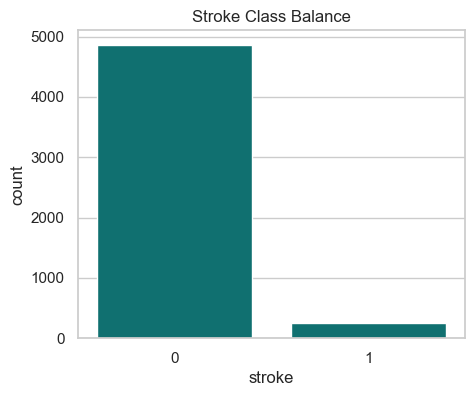

In [100]:
plt.figure(figsize=(5, 4))
sns.countplot(x='stroke', data=st, color='teal')
plt.title('Stroke Class Balance')
plt.show()

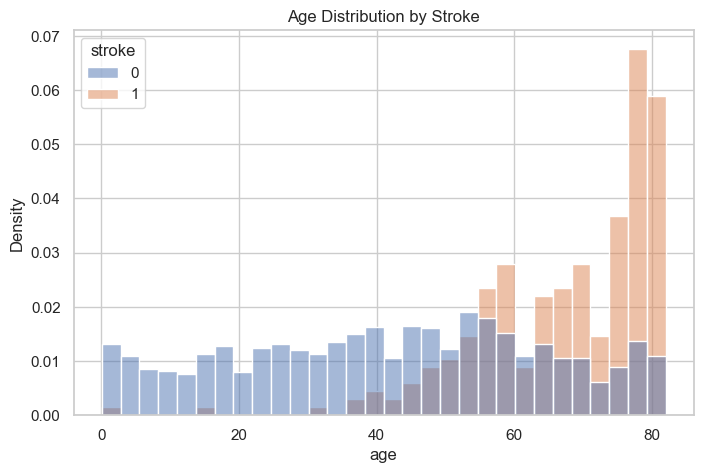

In [101]:
plt.figure(figsize=(8, 5))
sns.histplot(data=st, x='age', hue='stroke', bins=30, stat='density', common_norm=False)
plt.title('Age Distribution by Stroke')
plt.show()

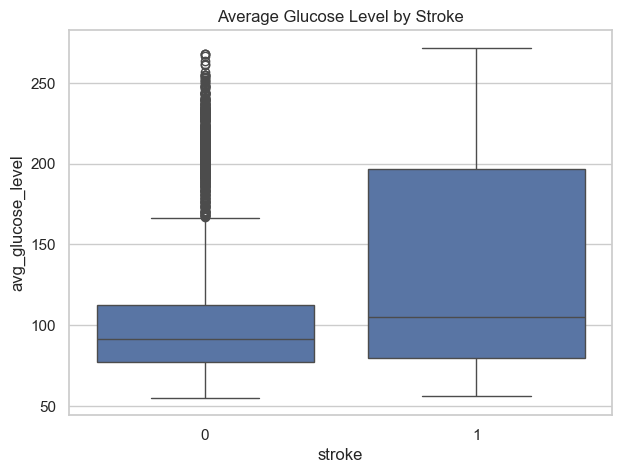

In [102]:
plt.figure(figsize=(7, 5))
sns.boxplot(x='stroke', y='avg_glucose_level', data=st)
plt.title('Average Glucose Level by Stroke')
plt.show()

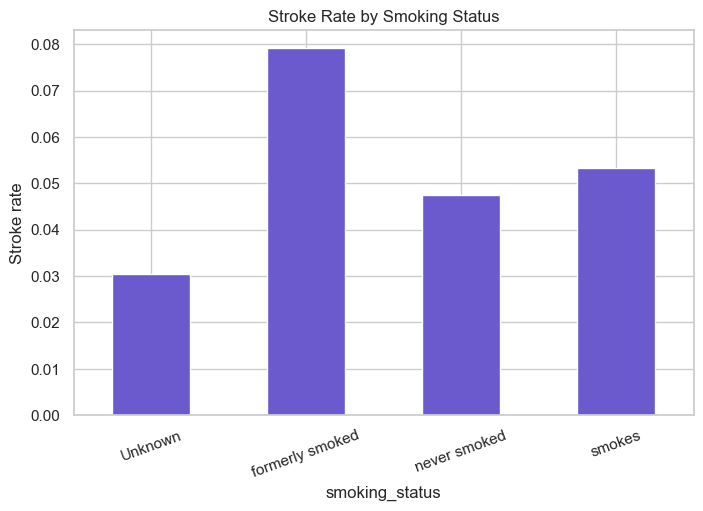

In [103]:
plt.figure(figsize=(8, 5))
st.groupby('smoking_status')['stroke'].mean().plot(kind='bar', color='slateblue')
plt.title('Stroke Rate by Smoking Status')
plt.ylabel('Stroke rate')
plt.xticks(rotation=20)
plt.show()

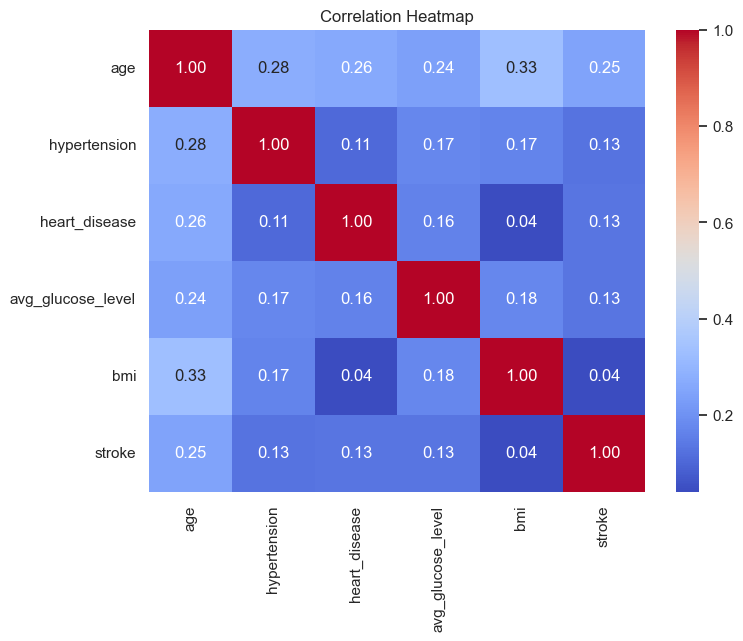

In [104]:
plt.figure(figsize=(8, 6))
sns.heatmap(st.drop(columns='id').select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()